<a href="https://colab.research.google.com/github/martin2758/Data-Analysis-Course/blob/main/S4_FlippedClassroom_Exercises_completed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Professor:** Christian Mata Miquel

**Subject:** Data Analysis & Pattern Recognition

**Module:** Exploratory Data Analysis

# **FLIPPED CLASSROOM (STUDENT VERSION)**

A flipped classroom is an instructional approach in which students first encounter new content on their own (e.g., via videos, readings, or online materials) before class, and then use class time for active, guided practice, problem solving, and discussion with the instructor's support.

### **Instructions**

This is **pre-class work**. Before the in-class session:

1. Review the theory notebook `Clustering_analysis_PRML` (k-means, hierarchical/agglomerative clustering, Gaussian Mixture Models, and evaluation metrics: confusion matrix, adjusted Rand score, BIC).
2. Complete the **3 exercises** below on your own. They combine skills from previous sessions:
   - **S1** (Python basics: functions, loops)
   - **S2.1** (pandas data handling, missing values, seaborn visualization)
   - **S3** (k-means, hierarchical clustering, GMM, evaluation metrics)
3. Bring your completed notebook (even if incomplete or with errors) and upload your solution to ATENEA (also share your GitHub link).
4. Three students will be randomly selected to present their solutions for Exercise 1, Exercise 2, and
Exercise 3. The student will come to present his solution and it will be discussed with all your classmates.

**No solutions are included here on purpose** — the goal is to try, get stuck, and bring your questions to class.

### **Before to start**

### Quick self-check before you start (answer in your own words, no need to submit)

- What is the main difference between k-means and hierarchical clustering in terms of how the number of clusters is chosen?
- Why can k-means fail on non-spherical or unevenly-sized clusters?
- What does the BIC criterion help us choose in a Gaussian Mixture Model?

If you can't answer these after reviewing the theory notebook, note it down — we'll start class with these questions.


**- What is the main difference between k-means and hierarchical clustering in terms of how the number of clusters is chosen?**

In k-means the numver of clusters is chosen based on prior knowledge or at random.

With hierarchical the number of clusters are chosen based on the either divisive or agglomerative hierarchy that is made first. This means the number of clusters is decided after creating hierarchies, as opposed to k-means where the amount of clusters is chosen first.


**- Why can k-means fail on non-spherical or unevenly-sized clusters?**
k-means fails on non-spherical clusters because it tries to minimize the distance to a single point - centroid, and if the data is ie. long, k-means might seperate the cluster into multiple smaller clusters.

k-means fails for unevenly-sized clusters, because if one cluster is significantly bigger than another, the big cluster will dominate the results. The k-means always tries to minimize the distance to the centroid, and therefore a small cluster might not be recognized because a bigger cluster will take all the centroids.

**What does the BIC criterion help us choose in a Gaussian Mixture Model?**

BIC is a score used to help decide on how many clusters to include.More clusters improve the fit of the data but adds complexity, the BIC, helps decide by penalizing complexity (many clusters), so that a compromise between good fit and simplicity is reached.


## **Exercise 1:** K-means on the Penguins dataset (S2 + S3)

We'll reuse the `penguins` dataset from the S2 session (Palmer Archipelago penguins), and now apply clustering to it.

```python
import seaborn as sns
penguins = sns.load_dataset('penguins')
```

a) **(S2.1 recap)** Keep only the numeric columns (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`). Before dropping anything, **check how many missing values** each column has (`.isna().sum()`). Then drop rows with missing values (`.dropna()`) and **confirm the resulting dataframe is clean** (no `NaN` left).

b) **(normalization)** The four numeric columns live on very different scales (millimeters vs. grams). **Normalize them** with `StandardScaler` (mean 0, standard deviation 1) before clustering, since k-means uses Euclidean distance and would otherwise let `body_mass_g` dominate the result just because its raw values are much larger.

c) Apply **k-means** with `n_clusters=3` (there are 3 penguin species) to the **normalized** columns. Store the resulting labels in a variable `kmeans_labels`.

d) Add the cluster labels as a new column in your (unscaled) dataframe, and make a **scatterplot** (`bill_length_mm` vs `flipper_length_mm`) colored by `kmeans_labels`, as done in the S3 notebook and in S2.1. Also make two **pairplots** of the four numeric variables: one colored by the real `species`, and one colored by `kmeans_labels`, to visually compare them side by side (as done with `hue` in S2.1).

e) Now compare the clusters found by k-means with the **real species** (`species` column). Compute a **confusion matrix** (`sklearn.metrics.confusion_matrix`) between `kmeans_labels` and the real species, and the **adjusted Rand score** (`adjusted_rand_score`).

f) In a short comment or markdown cell: does k-means recover the 3 species well? Which species seem to get confused with each other, if any? Did normalizing the features change the result compared to using the raw values?

In [4]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix
from sklearn.metrics.cluster import adjusted_rand_score
from sklearn.preprocessing import LabelEncoder, StandardScaler

penguins_original = sns.load_dataset('penguins')

#create a copy of the original that we work with to not change the original dataset
penguins = penguins_original.copy()

# a) YOUR CODE HERE: check missing values per column, then dropna() and confirm the data is clean
# Displays the first 10 rows
###display(penguins.head(10))
#checks amount of missing values in each column
###print(penguins.isna().sum())

# Define the numeric columns we want to keep
num_cols = ['bill_length_mm', 'bill_depth_mm',
            'flipper_length_mm', 'body_mass_g']

# Keep only the selected columns
penguins = penguins[num_cols]

# Remove rows with missing values
penguins_clean = penguins.dropna()

#Checks amout of NaN
###print(penguins_clean.isna().sum())

#display
###display(penguins_clean.head(10))

# b) YOUR CODE HERE: normalize the numeric columns with StandardScaler
# Create the scaler
scaler = StandardScaler()

# Normalize the data
penguins_scaled = scaler.fit_transform(penguins_clean)

# Display the normalized data
###print(penguins_scaled)

#Value calculated by: Original measurement minus mean of column divided by standard deviation
#A value of 0 means the measurement is at the column's average.
#A value of +1 means it is one standard deviation above average.
#A value of -1 means it is one standard deviation below average.

# c) YOUR CODE HERE: apply KMeans with n_clusters=3 on the normalized data
# Create the K-means model - random_state=5 is a randomly chosen number - it ensures the result is reproducible by reusing seed 5
kmeans = KMeans(n_clusters=3, random_state=5)

# Fit the model and store the cluster labels - each penguin has a number 0-2 storing it's label
kmeans_labels = kmeans.fit_predict(penguins_scaled)

# Display the labels
###print(kmeans_labels)

# d) YOUR CODE HERE: add kmeans_labels to penguins_clean, plot bill_length_mm vs flipper_length_mm colored by cluster,
#    and make two pairplots (one hue='species', one hue=kmeans cluster)

#adds a column for the label
penguins_clean['kmeans_labels'] = kmeans_labels
###display(penguins_clean.head(20))

###sns.scatterplot(
###    data=penguins_clean,
###    x='bill_length_mm',
###    y='flipper_length_mm',
###    hue='kmeans_labels'
###)

#create scatterplot
###plt.show()

#recreates the data from the original dataset, to have the unscaled datafram and the species
penguins_plot = penguins_original.dropna(subset=num_cols).copy()

#adds the column kmeans_lavels and fills it with the results from part c
penguins_plot['kmeans_labels'] = kmeans_labels
###display(penguins_plot)

# Creates a pairplot coloured by the penguin species
###sns.pairplot(
###    data=penguins_plot,
###    vars=num_cols,
###    hue='species'
###)

###plt.show()

# Creates a pairplot coloured by the clusters identified by K-means
###sns.pairplot(
###    data=penguins_plot,
###    vars=num_cols,
###    hue='kmeans_labels'
###)

###plt.show()

# e) YOUR CODE HERE: confusion matrix and adjusted Rand score vs real 'species'

# Creates an encoder to convert categories into numbers
encoder = LabelEncoder()
# Converts species names into numerical labels
species_labels = encoder.fit_transform(penguins_plot['species'])

# Compares real species labels with K-means clusters. 1st row shows 128 of the first species are in cluster 0 and 23 in cluster 2. 3rd row is thirds species - perfect match cluster 1.
cm = confusion_matrix(species_labels, kmeans_labels)
print(cm)

# Adjusted Rand score - a score that summarizes how well grouping fits. Closer to 1 is strong fit, we have 0,799 which is a strong agreement.
ari = adjusted_rand_score(species_labels, kmeans_labels)
print("Adjusted Rand score:", ari)

# f) YOUR CODE HERE (as a comment or markdown cell): interpretation
#K-means recovers the three species quite well, with an adjusted Rand score of 0,799. One species is separated perfectly into its own
#cluster, while species 1 and 3 get confused with each other sometimes. Normalization is important because the features have different
#scales. Normalization likely improved the results because body_mass_g has much larger numerical values than the measurements in millimeters.
#which would cause the K-means to focus too heavily on weight (euclidean distance calculation).


[[128   0  23]
 [  5   0  63]
 [  0 123   0]]
Adjusted Rand score: 0.7990236904936548


/tmp/ipykernel_1631/3190402752.py:65: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  penguins_clean['kmeans_labels'] = kmeans_labels


---

## **Exercise 2:** Hierarchical clustering + a custom distance function (S1 + S3)

We'll use the small synthetic dataset from the S3 notebook:

```python
import numpy as np
X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])
```

a) **(control de datos)** Even on a small synthetic array like this one, it's good practice to check for missing values before doing anything else: use `np.isnan(X).any()` to confirm there are none.

b) **(normalization)** Normalize `X` with `StandardScaler` before clustering (even though both coordinates here happen to be on a similar scale, this should always be the default first step for any distance-based method, so that you don't forget it on a real dataset where scales usually differ a lot).

c) **(S1 recap)** Write a plain Python function `euclidean_distance(p1, p2)` **without using numpy or sklearn**, using only a `for` loop over the coordinates, that computes the Euclidean distance between two points (given as lists or tuples). Test it on `euclidean_distance(X[0], X[3])` and check it against `np.linalg.norm(X[0]-X[3])`.

d) Apply **Agglomerative Clustering** with `n_clusters=2` to the **normalized** `X` (as done in the S3 notebook), and plot the **dendrogram** using `scipy.cluster.hierarchy.dendrogram` and `linkage`.

e) Also apply **k-means** with `n_clusters=2` to the same normalized data.

f) Compare the cluster labels obtained by agglomerative clustering and k-means — are they identical for this small dataset? (Print both label arrays, and make a side-by-side scatterplot of the original points colored by each method's labels.)

g) **(S1 recap)** Write a function `cluster_sizes(labels)` that takes an array of cluster labels and returns a **dictionary** with the count of observations per cluster (reuse the dictionary-counting pattern from S1), and apply it to both clusterings.

In [7]:
import numpy as np
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])

# a) YOUR CODE HERE: check for missing values with np.isnan(X).any()
#check for missing values
###print(np.isnan(X).any())


# b) YOUR CODE HERE: normalize X with StandardScaler
# Create the standard scaler
scaler = StandardScaler()
# Normalize X using its mean and standard deviation
X_scaled = scaler.fit_transform(X)
###print(X_scaled)

# c) YOUR CODE HERE: plain-Python euclidean_distance function using a for loop (no numpy/sklearn)
def euclidean_distance(p1, p2):                  # Define a function that takes two points, so we can calculate the distance between any 2 points
    sum_squared = 0                              # create a variable that starts at zero
    for i in range(len(p1)):                     # Loops through every coordinate in p1 - len(p1) gives us how many coordinates there are
        sum_squared += (p1[i] - p2[i]) ** 2      # Calculated the squared difference between the current coordinates and cumulates the results in the variable
    return sum_squared ** 0.5                    # Takes the square root of the result and returns the answer
#we take the squared and then the root - because of pythagorean a^2+b^2 = c^2

# Test the function
###print(euclidean_distance(X[0], X[3]))        # Calculate the distance between the first and fourth points, to verify it works
###print(np.linalg.norm(X[0] - X[3]))               # Check the result by printing the distance between the first and fourth point
#We want the 2 exact responses to verify the function works - it does

# d) YOUR CODE HERE: agglomerative clustering on X_scaled + dendrogram
# Apply agglomerative clustering to the normalized data
model = AgglomerativeClustering(n_clusters=2)  # Create a Agglomerative model with 2 clusters, as specified in the task
labels = model.fit_predict(X_scaled)            # runs the clustering algorithm on X_scaled and assigns each point to a cluster
###print(labels)                                    # Print the cluster assigned to each point

# Plot the dendrogram
###Z = linkage(X_scaled, method='ward')             # Calculated which clusters should merge next in the hierachy, using the "ward" method
###plt.figure(figsize=(8, 5))                       # Create a figure for the dendrogram, and determines it's size
###dendrogram(Z)                                    # draws the dendrogram
###plt.title("Hierarchical Clustering Dendrogram")  # Add a title to the plot
###plt.xlabel("Data points")                        # Label the horizontal axis
###plt.ylabel("Distance")                           # Label the vertical axis
###plt.show()                                       # Display the dendrogram


# e) YOUR CODE HERE: k-means clustering with n_clusters=2 on X_scaled
# Apply K-means to the normalized data
kmeans = KMeans(n_clusters=2, random_state=5)  # Create a K-means model with 2 clusters - choosing random state for reproducability
kmeans_labels = kmeans.fit_predict(X_scaled)    # runs K-means on the normalized data and assigns each point to a cluster
###print(kmeans_labels)                             # Print the cluster labels

# f) YOUR CODE HERE: compare both label arrays and make a side-by-side scatterplot
# Compare the cluster labels
###print(labels)             # Print the agglomerative cluster assignments
###print(kmeans_labels)      # Print the K-means cluster assignments

# Create side-by-side scatterplots
###plt.figure(figsize=(10, 4))                  # Create a figure for both plots, and determines size

###plt.subplot(1, 2, 1)                         # Makes room for 2 plots (1 row 2 columns of plots) and selects the first plot
###plt.scatter(X[:, 0], X[:, 1], c=labels)      # Plot original points colored by agglomerative labels
###plt.title("Agglomerative Clustering")        # Add a title to the first plot
###plt.xlabel("X coordinate")                   # Label the horizontal axis
###plt.ylabel("Y coordinate")                   # Label the vertical axis

###plt.subplot(1, 2, 2)                         # Create the second plot on the right
###plt.scatter(X[:, 0], X[:, 1], c=kmeans_labels) # Plot original points colored by K-means labels
###plt.title("K-means Clustering")              # Add a title to the second plot
###plt.xlabel("X coordinate")                   # Label the horizontal axis
###plt.ylabel("Y coordinate")                   # Label the vertical axis

###plt.show()                                   # Display both plots

#they are not identical, however if i change the random-state they can become identical

# g) YOUR CODE HERE: cluster_sizes function using a dictionary
# Define a function to count observations per cluster
def cluster_sizes(labels):                  # Define a function that takes cluster label arrays as input
    sizes = {}                              # Create an empty dictionary
    for label in labels:                    # Go through each label in "labels"
        if label in sizes:                  # Check if the label is already in the dictionary
            sizes[label] += 1               # Add one to its count
        else:                               # If the label is not in the dictionary yet
            sizes[label] = 1                # Start its count at one
    return sizes                            # Return the dictionary with cluster sizes

# Apply the function to both clustering methods
print(cluster_sizes(labels))                # Print agglomerative cluster sizes
print(cluster_sizes(kmeans_labels))         # Print K-means cluster sizes


{np.int64(1): 3, np.int64(0): 3}
{np.int32(0): 4, np.int32(1): 2}


---

## **Exercise 3:** Choosing the number of clusters with GMM + BIC (S1+S2+S3)

We'll reuse the `diamonds` sample from the S2.1 session:

```python
diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
```

a) **(S2 recap)** Select only the numeric columns `carat`, `depth`, `table`, `price` into a new dataframe `diamonds_num`. **Check for missing values** (`.isna().sum()`) and drop any rows with `NaN` if needed, confirming the data is clean afterwards.

b) **(exploración, opcional pero recomendado)** Plot the distribution of `price` (histogram) and mark the mean and mean ± one standard deviation with vertical lines, as done in S2.1 — this helps you see just how skewed and large-scale `price` is compared to the other three variables.

c) **(normalization)** `carat`, `depth`, `table` and `price` are on very different scales (price ranges into the thousands of dollars, while depth/table are percentages around 50–70). **Normalize all four columns with `StandardScaler`** before fitting the GMM — otherwise `price` alone will dominate the covariance structure the model is trying to fit.

d) As done in the S3 notebook, fit a **Gaussian Mixture Model** on the **normalized** data for a range of number of components from 1 to 8, store the **BIC** value for each in a list, and plot BIC vs number of components.

e) Find the number of components that **minimizes** the BIC, and fit the final GMM model with that number of components. Store the predicted cluster labels in `gmm_labels`.

f) Add `gmm_labels` as a new column to your (unscaled, more interpretable) `diamonds_num` and create a **pairplot** (`sns.pairplot`) of `carat`, `depth`, `table`, `price`, colored by `gmm_labels` (`hue`), as done in S2.1. Also make a **jointplot** (`sns.jointplot`) of `carat` vs `price` to zoom into the relationship driving most of the clustering.

g) In a short comment or markdown cell: does the optimal number of clusters found by BIC seem reasonable when you look at the pairplot? Would you have guessed the same number just by eye? Did normalizing the data change the optimal number of components compared to fitting the GMM on the raw values?

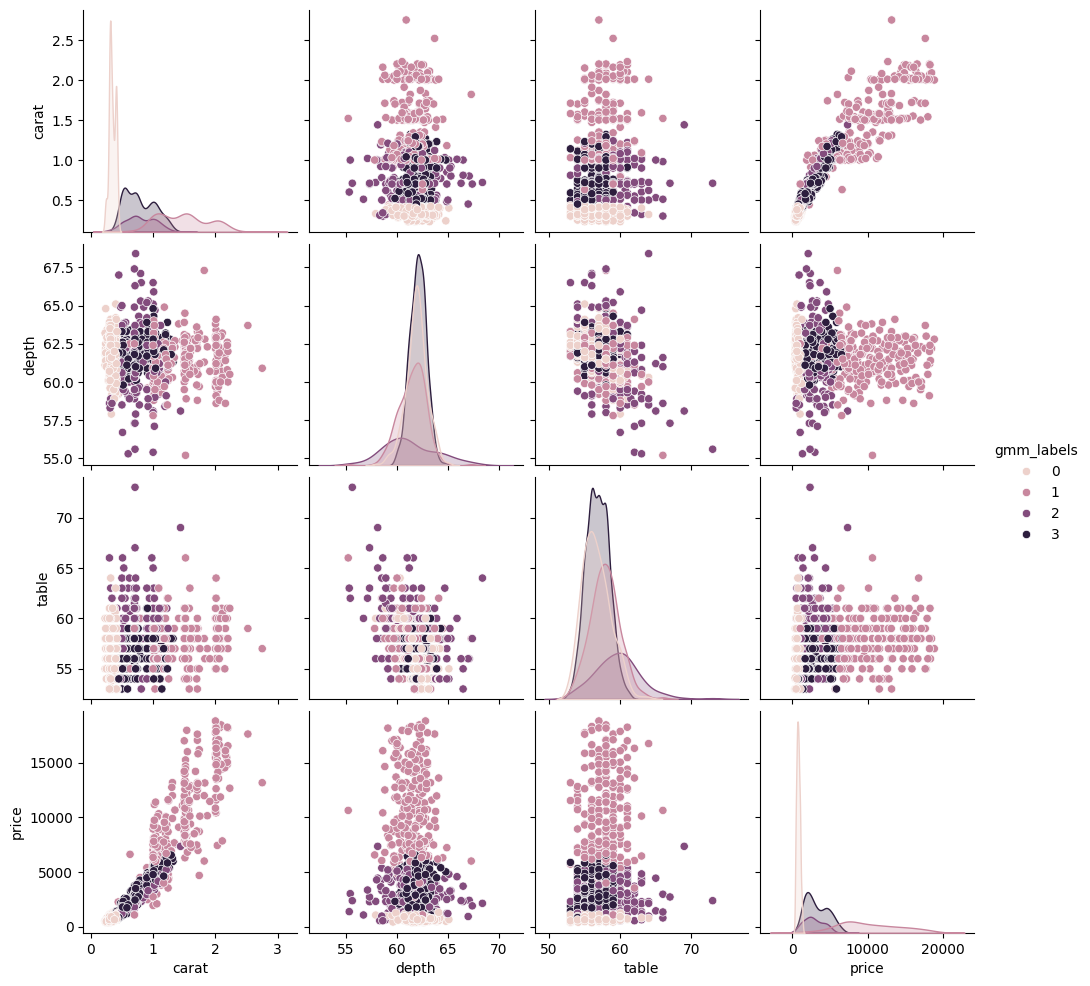

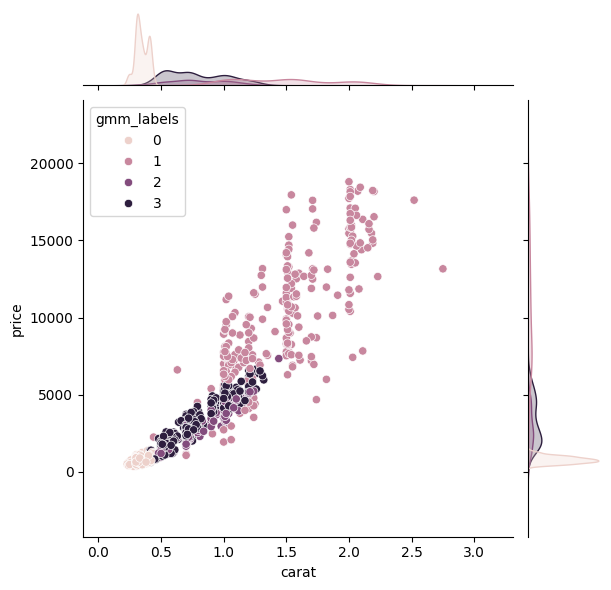

4


In [29]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import mixture
from sklearn.preprocessing import StandardScaler

diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)

# a) YOUR CODE HERE: select numeric columns into diamonds_num, check missing values, dropna() and confirm it's clean

# Selects only the four numerical columns, and puts in a new variable so we don't change the original dataset.
diamonds_num = diamonds[['carat', 'depth', 'table', 'price']]

# Count the missing values (NaN) in each column
###print(diamonds_num.isna().sum())

# Remove any rows that contain at least one missing value
diamonds_num = diamonds_num.dropna()

# Check the missing values again to confirm the data is clean
###print(diamonds_num.isna().sum())

#The data was already clean, so it wasn't necessary to .dropna

# b) YOUR CODE HERE: histogram of 'price' with mean and mean +/- std lines

# Calculate the mean price (average)
mean_price = diamonds_num['price'].mean()

# Calculate the standard deviation of price
std_price = diamonds_num['price'].std()

# Plot a histogram showing the distribution of prices. bins=30 divides it into 30 intervals.
###plt.hist(diamonds_num['price'], bins=30, edgecolor='black')

# Add a vertical line at the mean. linestyle makes the line solid.
###plt.axvline(mean_price, color='red', linestyle='-', label='Mean')

# Add a vertical line at mean minus one standard deviation, linestyle makes it dashed.
###plt.axvline(mean_price - std_price, color='green', linestyle='--', label='Mean - 1 Std')

# Add a vertical line at mean plus one standard deviation, linestyle makes it dashed.
###plt.axvline(mean_price + std_price, color='orange', linestyle='--', label='Mean + 1 Std')

# Add a title and labels to the axes
###plt.title('Distribution of Diamond Prices')
###plt.xlabel('Price')
###plt.ylabel('Frequency')

# Display the legend and the plot. Legend is the small box in top right corner.
###plt.legend()
###plt.show()


# c) YOUR CODE HERE: normalize the 4 numeric columns with StandardScaler

# Create a StandardScaler object to standardize the data
scaler = StandardScaler()

# Fit calculates mean and std deviation. transform standardizes the values with formula original value - mean divided by std deviation.
diamonds_scaled = scaler.fit_transform(diamonds_num)

# after transforming we have a array of data, not a panda dataframe. We refit into panda dataframe, and gives it the column names again.
diamonds_scaled = pd.DataFrame(diamonds_scaled, columns=diamonds_num.columns)

# Check the first five rows of the normalized data
###print(diamonds_scaled.head())

# Check the mean of each normalized column
###print(diamonds_scaled.mean())

# Check the standard deviation of each normalized column
###print(diamonds_scaled.std())


# d) YOUR CODE HERE: fit GMM for n_components = 1..8 on diamonds_scaled, store BIC values, plot BIC vs n_components

# Create a list of the number of components to test, from 1 to 8. When using range in python the last number (9) is not included, but 1 is.
n_components_range = range(1, 9)

# Create an empty list to store the BIC value for each model
bic = []

# runs the code once for each value of n from 1 to 8
for n in n_components_range:

    # Create a Gaussian Mixture Model. n_components=n specifies how many gaussian components to include in that iteration.
    gmm = mixture.GaussianMixture(n_components=n, random_state=42)

    # trains the model on the normalized data
    gmm.fit(diamonds_scaled)

    # Calculate the BIC score and add it to the list
    bic.append(gmm.bic(diamonds_scaled))

# Plot the BIC scores against the number of components. n_components are x coordinates and bic are y. Marker=o adds a circle at each point.
###plt.plot(n_components_range, bic, marker='o')

# Add a title and labels to the axes
###plt.title('BIC vs Number of GMM Components')
###plt.xlabel('Number of Components')
###plt.ylabel('BIC')

# Display the plot
###plt.show()

#We can now visually see what number of components has a good fit to complexity rating. We can see 1 is by far the worst.


# e) YOUR CODE HERE: find the number of components that minimizes BIC and fit the final GMM
# np.argmin finds the index position (place in array) of the lowest value.
best_n = n_components_range[np.argmin(bic)]

# Create a GMM model using the best number of components
gmm = mixture.GaussianMixture(n_components=best_n, random_state=42)

# trains the model on the normalized data.
gmm.fit(diamonds_scaled)

# Predict the cluster label for each diamond
gmm_labels = gmm.predict(diamonds_scaled)

###print(gmm_labels)

# f) YOUR CODE HERE: add gmm_labels to diamonds_num (unscaled) and make a pairplot + a jointplot (carat vs price)
# Adds a column with each diamnods predicted cluster to the original data
diamonds_num['gmm_labels'] = gmm_labels

# Create a pairplot showing relationships between all four numerical variables. Pairplot expects the data first so i don't need to specify data=...
sns.pairplot(diamonds_num, vars=['carat', 'depth', 'table', 'price'], hue='gmm_labels')

# Display the pairplot
plt.show()

# Create a jointplot showing the relationship between carat and price.
sns.jointplot(data=diamonds_num, x='carat', y='price', hue='gmm_labels')

# Display the jointplot
plt.show()


# g) YOUR CODE HERE (as a comment or markdown cell): interpretation
print(best_n)
#Looking at the pairplot it does seem, quite reasonable, however it is very difficult to approximate teh amount of clusters in this data
#by eye. I wouldn't have known what to guess simply by eye, so no i wouldn't say 4 clusters is obvious.
#without knowing if i would have gotten the lowest BIC of 4 without normalizing the data, it is likely that normalizing the data has changed
#the outcome. Because the price had much higher numerical values and differenes, it is likely the model would have created clusters nearly
#exclusively based on price, rather than using all 4 parameters.
